In [9]:
# Dataset overview
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Shape:")
print(df.shape)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                500 non-null    int64  
 1   sex                500 non-null    str    
 2   blood_pressure     500 non-null    int64  
 3   cholesterol        500 non-null    int64  
 4   bmi                500 non-null    float64
 5   smoker             500 non-null    str    
 6   diabetes           500 non-null    str    
 7   physical_activity  500 non-null    int64  
 8   family_history     500 non-null    str    
 9   stress_level       500 non-null    int64  
 10  heart_disease      500 non-null    int64  
dtypes: float64(1), int64(6), str(4)
memory usage: 49.2 KB

Statistical Summary:


,age,blood_pressure,cholesterol,bmi,physical_activity,stress_level,heart_disease
count,500.000000,500.000000,500.00000,500.000000,500.000000,500.000000,500.000000
mean,54.864000,132.874000,221.50000,29.020400,2.048000,4.876000,0.532000
std,14.315004,26.418516,43.86363,6.400954,1.421879,2.595013,0.499475
min,30.000000,90.000000,150.00000,18.100000,0.000000,1.000000,0.000000
25%,43.000000,111.000000,183.75000,23.275000,1.000000,3.000000,0.000000
50%,55.000000,132.000000,221.00000,29.200000,2.000000,5.000000,1.000000
75%,66.250000,155.000000,258.00000,34.525000,3.000000,7.000000,1.000000
max,79.000000,179.000000,299.00000,40.000000,4.000000,9.000000,1.000000



Column Names:
['age', 'sex', 'blood_pressure', 'cholesterol', 'bmi', 'smoker', 'diabetes', 'physical_activity', 'family_history', 'stress_level', 'heart_disease']

Dataset Shape:
(500, 11)


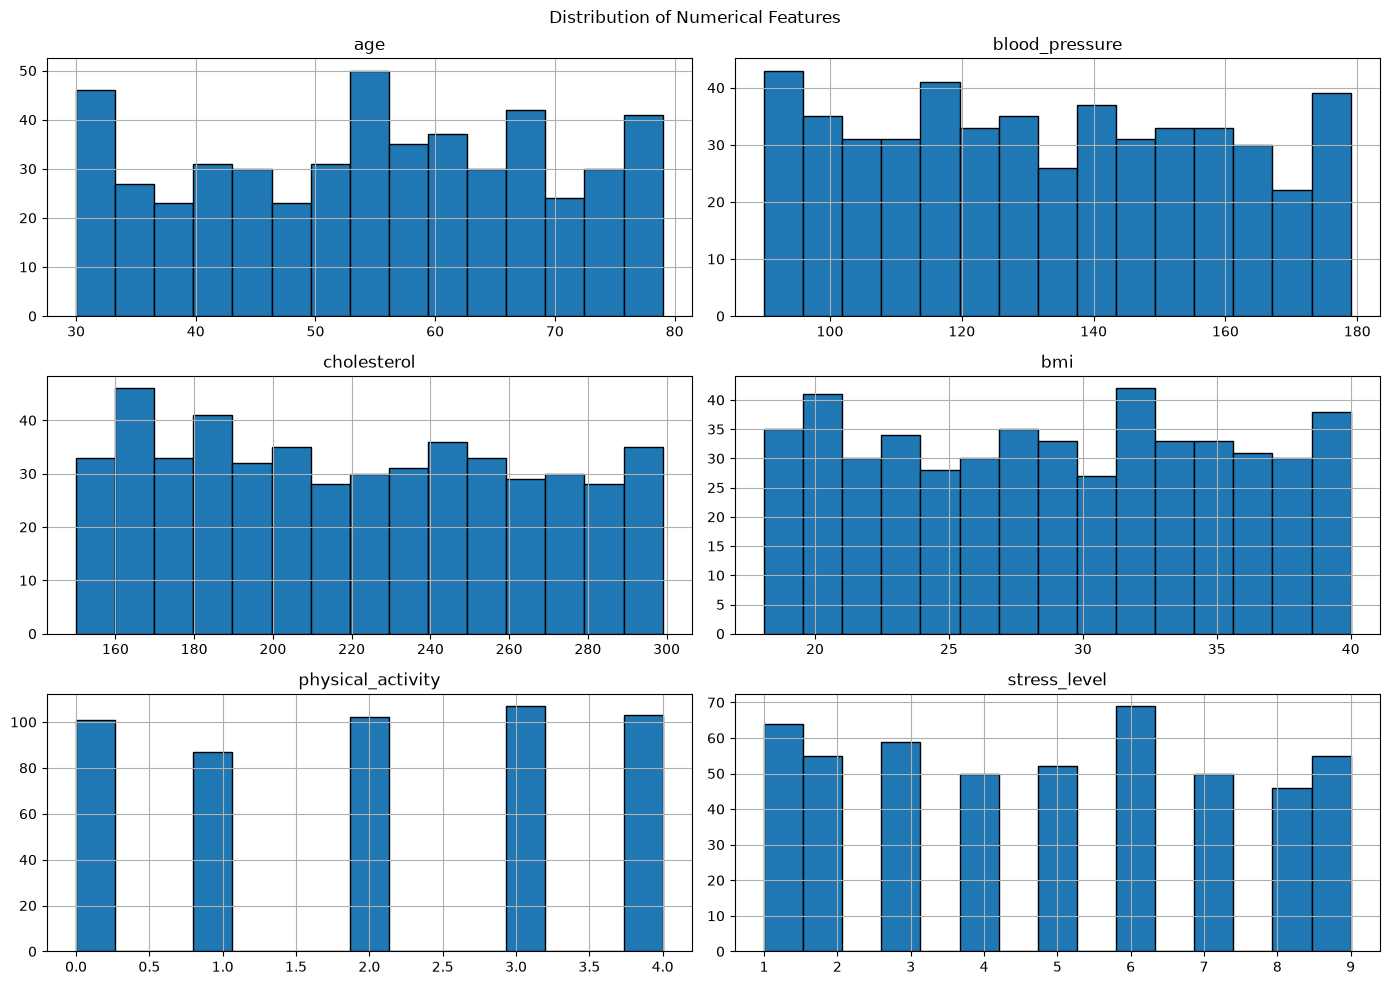

In [12]:
# Distribution of numerical features

numerical_columns = [
    "age",
    "blood_pressure",
    "cholesterol",
    "bmi",
    "physical_activity",
    "stress_level"
]

df[numerical_columns].hist(
    figsize=(14, 10),
    bins=15,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

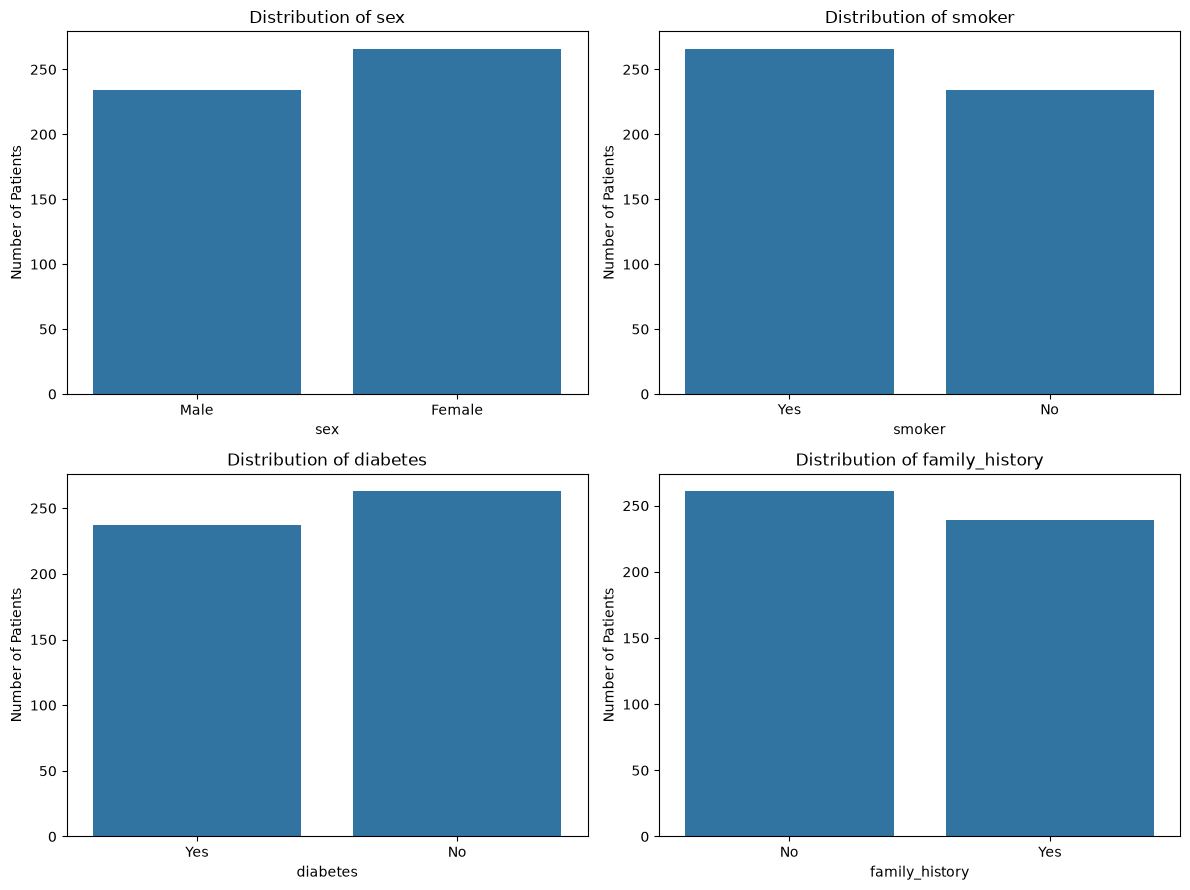

In [13]:
# Distribution of categorical features

categorical_columns = [
    "sex",
    "smoker",
    "diabetes",
    "family_history"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for column, ax in zip(categorical_columns, axes.flatten()):
    sns.countplot(data=df, x=column, ax=ax)
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Number of Patients")

plt.tight_layout()
plt.show()

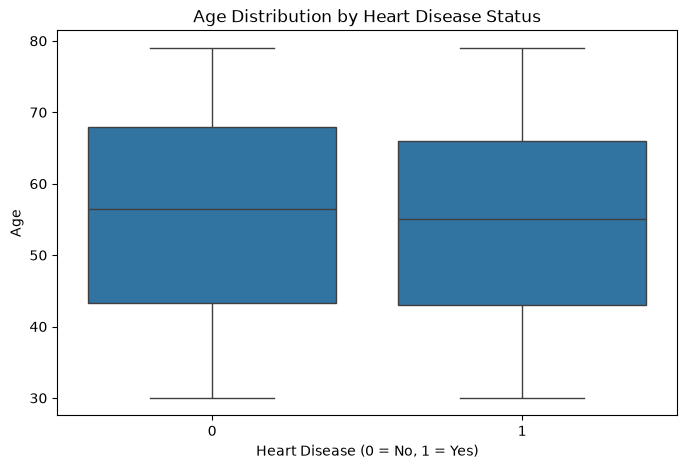

In [14]:
# Heart disease by age
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="heart_disease", y="age")

plt.title("Age Distribution by Heart Disease Status")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Age")

plt.show()

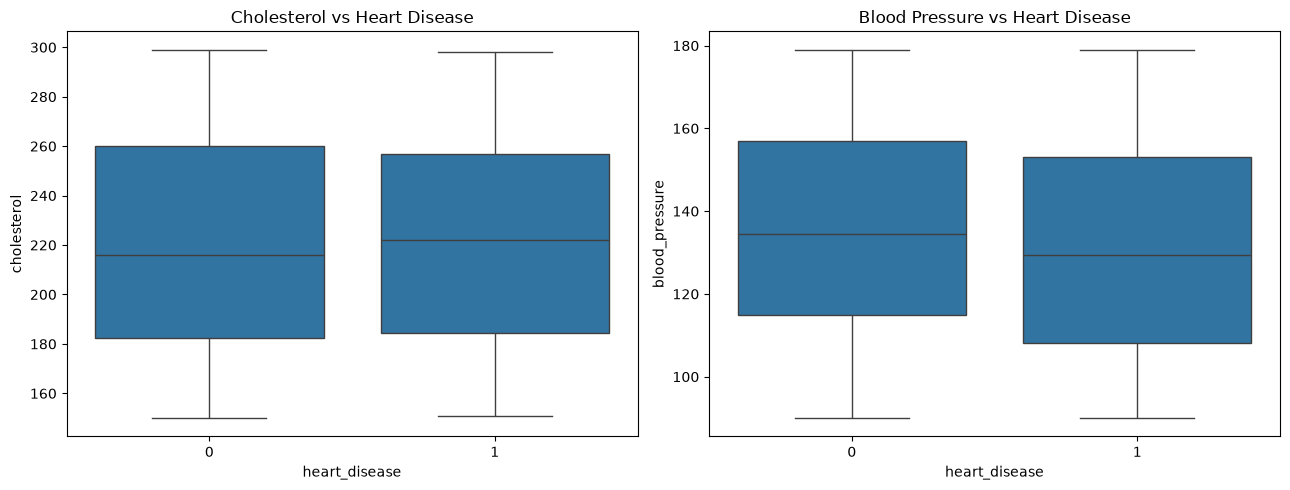

In [15]:
# Cholesterol and blood pressure comparisons

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=df, x="heart_disease",
    y="cholesterol", ax=axes[0]
)
axes[0].set_title("Cholesterol vs Heart Disease")

sns.boxplot(
    data=df, x="heart_disease",
    y="blood_pressure", ax=axes[1]
)
axes[1].set_title("Blood Pressure vs Heart Disease")

plt.tight_layout()
plt.show()

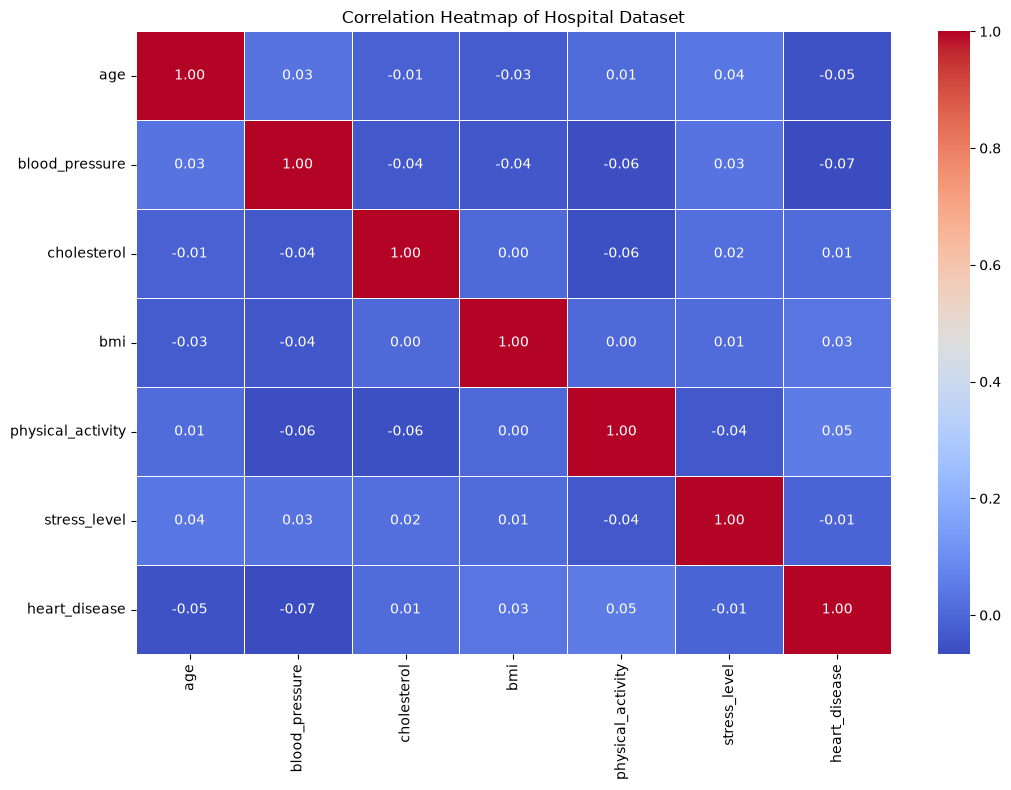

In [16]:
# Correlation heatmap

plt.figure(figsize=(11, 8))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Hospital Dataset")
plt.tight_layout()
plt.show()

In [17]:
# Separate input features and target variable

X = df.drop("heart_disease", axis=1)

y = df["heart_disease"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Features shape: (500, 10)
Target shape: (500,)

Input Features:
   age     sex  blood_pressure  cholesterol   bmi smoker diabetes  \
0   68    Male             105          191  38.0    Yes      Yes   
1   58  Female              97          249  22.0    Yes      Yes   
2   44  Female              93          190  23.2     No      Yes   
3   72    Male              93          183  39.4     No       No   
4   37  Female             145          166  22.0     No      Yes   

   physical_activity family_history  stress_level  
0                  0             No             2  
1                  0             No             4  
2                  0             No             8  
3                  3            Yes             1  
4                  4            Yes             1  

Target Variable:
0    0
1    0
2    0
3    0
4    0
Name: heart_disease, dtype: int64


In [18]:
# Identify numerical and categorical columns

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['age', 'blood_pressure', 'cholesterol', 'bmi', 'physical_activity', 'stress_level']

Categorical Features:
['sex', 'smoker', 'diabetes', 'family_history']


C:\Users\alfre\AppData\Local\Temp\ipykernel_8724\1267643449.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (400, 10)
Testing features: (100, 10)
Training target: (400,)
Testing target: (100,)


In [20]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Numerical preprocessing
numerical_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Fit on training data and transform
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("Processed training data:", X_train_processed.shape)
print("Processed testing data:", X_test_processed.shape)

Processed training data: (400, 14)
Processed testing data: (100, 14)


In [21]:
print("Training data ready:", X_train_processed.shape)
print("Testing data ready:", X_test_processed.shape)

print("\nMissing values in original dataset:")
print(df.isnull().sum().sum())

Training data ready: (400, 14)
Testing data ready: (100, 14)

Missing values in original dataset:
0


In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Classification algorithms imported successfully!")

Classification algorithms imported successfully!


In [23]:
# Initialize the models

models = {
    "Logistic Regression": LogisticRegression(
        random_state=42,
        max_iter=1000
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

# Train each model
for name, model in models.items():
    model.fit(X_train_processed, y_train)
    print(name, "trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


In [24]:
results = []

for name, model in models.items():

    predictions = model.predict(X_test_processed)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression      0.56     0.5616  0.7736    0.6508
1        Decision Tree      0.52     0.5410  0.6226    0.5789
2        Random Forest      0.54     0.5686  0.5472    0.5577


Confusion Matrix:
[[15 32]
 [12 41]]


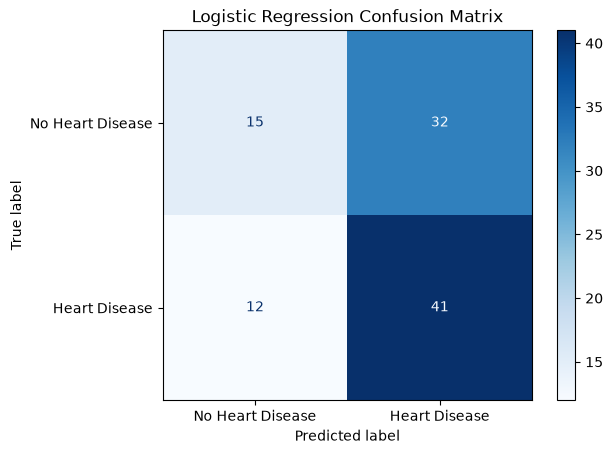


Classification Report:
                  precision    recall  f1-score   support

No Heart Disease       0.56      0.32      0.41        47
   Heart Disease       0.56      0.77      0.65        53

        accuracy                           0.56       100
       macro avg       0.56      0.55      0.53       100
    weighted avg       0.56      0.56      0.54       100



In [25]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

# Select Logistic Regression
best_model = models["Logistic Regression"]

# Generate predictions
y_pred = best_model.predict(X_test_processed)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Heart Disease", "Heart Disease"]
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Heart Disease", "Heart Disease"]
))

Confusion Matrix:
[[15 32]
 [12 41]]


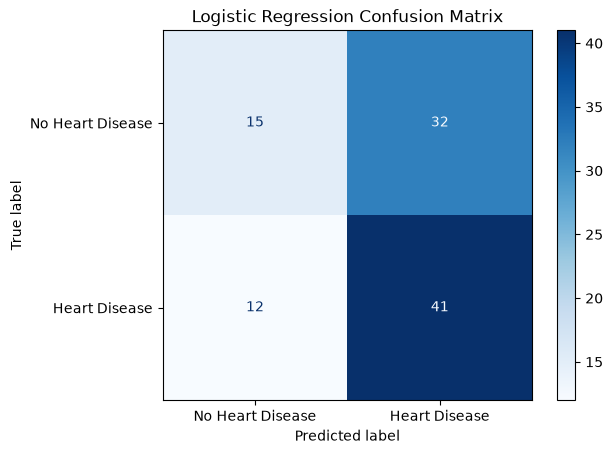

In [27]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report

# Select Logistic Regression
best_model = models["Logistic Regression"]

# Generate predictions
y_pred = best_model.predict(X_test_processed)

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Visualize confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Heart Disease", "Heart Disease"]
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [28]:
print("Classification Report:")

print(classification_report(
    y_test,
    y_pred,
    target_names=[
        "No Heart Disease",
        "Heart Disease"
    ]
))

Classification Report:
                  precision    recall  f1-score   support

No Heart Disease       0.56      0.32      0.41        47
   Heart Disease       0.56      0.77      0.65        53

        accuracy                           0.56       100
       macro avg       0.56      0.55      0.53       100
    weighted avg       0.56      0.56      0.54       100



In [29]:
import joblib
import os

# Create models folder if necessary
os.makedirs("../models", exist_ok=True)

# Save model and preprocessing together
model_package = {
    "model": best_model,
    "preprocessor": preprocessor,
    "features": X.columns.tolist()
}

joblib.dump(
    model_package,
    "../models/hospital_heart_disease_model.pkl"
)

print("Model and preprocessor saved successfully!")

Model and preprocessor saved successfully!


In [26]:
# Investigate numerical features against heart disease

print("Average values by heart disease status:")

display(
    df.groupby("heart_disease")[
        ["age", "blood_pressure", "cholesterol",
         "bmi", "physical_activity", "stress_level"]
    ].mean().round(2)
)

# Investigate categorical features

for column in [
    "sex", "smoker", "diabetes", "family_history"
]:
    print(f"\n{column} vs heart disease:")
    print(pd.crosstab(
        df[column],
        df["heart_disease"],
        normalize="index"
    ).round(3))

Average values by heart disease status:


,age,blood_pressure,cholesterol,bmi,physical_activity,stress_level
heart_disease,,,,,,
0,55.65,134.76,221.08,28.79,1.97,4.89
1,54.17,131.21,221.87,29.22,2.12,4.86



sex vs heart disease:
heart_disease      0      1
sex                        
Female         0.481  0.519
Male           0.453  0.547

smoker vs heart disease:
heart_disease      0      1
smoker                     
No             0.517  0.483
Yes            0.425  0.575

diabetes vs heart disease:
heart_disease      0      1
diabetes                   
No             0.460  0.540
Yes            0.477  0.523

family_history vs heart disease:
heart_disease       0      1
family_history              
No              0.467  0.533
Yes             0.469  0.531


In [31]:
import sklearn
import pandas as pd
import joblib

print("Scikit-learn:", sklearn.__version__)
print("Pandas:", pd.__version__)
print("Joblib:", joblib.__version__)

Scikit-learn: 1.9.1
Pandas: 3.1.0
Joblib: 1.6.0


In [10]:
# Check data types
print("Data Types:")
print(df.dtypes)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicates
print("\nDuplicate Records:")
print(df.duplicated().sum())

Data Types:
age                    int64
sex                      str
blood_pressure         int64
cholesterol            int64
bmi                  float64
smoker                   str
diabetes                 str
physical_activity      int64
family_history           str
stress_level           int64
heart_disease          int64
dtype: object

Missing Values:
age                  0
sex                  0
blood_pressure       0
cholesterol          0
bmi                  0
smoker               0
diabetes             0
physical_activity    0
family_history       0
stress_level         0
heart_disease        0
dtype: int64

Duplicate Records:
0


heart_disease
1    266
0    234
Name: count, dtype: int64


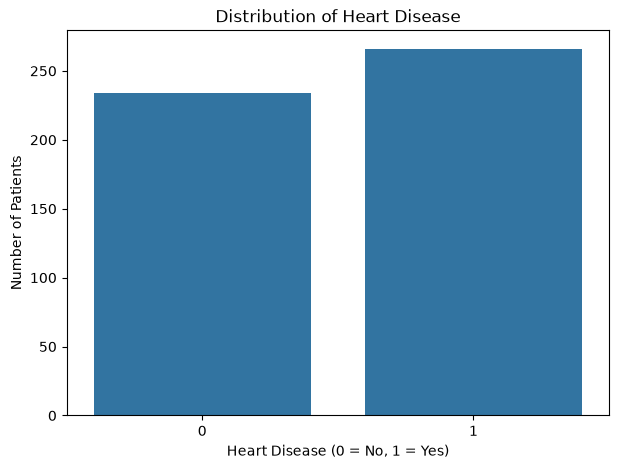

In [11]:
# Heart disease distribution
print(df["heart_disease"].value_counts())

# Visualize target distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="heart_disease")

plt.title("Distribution of Heart Disease")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")

plt.show()

In [8]:
df= pd.read_csv(file_path, encoding="utf-8")
print(df.head())
print("Dataset shape:",df.shape)

   age     sex  blood_pressure  cholesterol   bmi smoker diabetes  \
0   68    Male             105          191  38.0    Yes      Yes   
1   58  Female              97          249  22.0    Yes      Yes   
2   44  Female              93          190  23.2     No      Yes   
3   72    Male              93          183  39.4     No       No   
4   37  Female             145          166  22.0     No      Yes   

   physical_activity family_history  stress_level  heart_disease  
0                  0             No             2              0  
1                  0             No             4              0  
2                  0             No             8              0  
3                  3            Yes             1              0  
4                  4            Yes             1              0  
Dataset shape: (500, 11)


In [7]:
file_path ="../data/hospital_synthetic_dataset.xlsx.csv"
with open(file_path, "r", encoding="utf-8") as file: 
    print(file.read(500))

age,sex,blood_pressure,cholesterol,bmi,smoker,diabetes,physical_activity,family_history,stress_level,heart_disease
68,Male,105,191,38,Yes,Yes,0,No,2,0
58,Female,97,249,22,Yes,Yes,0,No,4,0
44,Female,93,190,23.2,No,Yes,0,No,8,0
72,Male,93,183,39.4,No,No,3,Yes,1,0
37,Female,145,166,22,No,Yes,4,Yes,1,0
50,Male,114,271,36.8,Yes,No,2,Yes,5,0
68,Male,156,225,28.8,No,Yes,1,No,5,1
48,Female,156,236,23.4,Yes,No,3,Yes,1,1
52,Female,116,266,37.2,No,Yes,2,No,6,1
40,Male,121,255,27.8,No,No,4,Yes,1,0
40,Male,1


In [3]:
import os
file_path= "../data/hospital_synthetic_dataset.xlsx.csv"

print("file exists:",os.path.exists(file_path))
print("file size:",os.path.getsize(file_path),"bytes")

file exists: True
file size: 19725 bytes


In [2]:
import os
print(os.getcwd())
print(os.listdir("../data"))

c:\Users\alfre\Desktop\Hospital_ML_PUIT22210085\notebooks
['hospital_synthetic_dataset.xlsx.csv']
